# 04 · Linear Models: Linear Regression, Ridge, Lasso, ElasticNet

**Goal:** fit the readable models first (lessons 02 and 12):

1. decide between `price` and `log(price)` as the target, using cross-validation on the training set;
2. tune Ridge, Lasso and ElasticNet with `GridSearchCV` (lesson 13);
3. score each model once on the test set;
4. read the coefficients as "% change in price", the part the audience will remember.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

sys.path.append('../src')
from prep import (load_data, split, add_model_top, linear_preprocessor, evaluate,
                  cv_dollars, save_result, save_params, RANDOM_STATE)

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
X_train, X_test = add_model_top(X_train, X_test)
y_train_log = np.log(y_train)
print(X_train.shape, X_test.shape)

(166115, 20) (41529, 20)


## 1. Target choice: price vs log(price)

Same model and features, 5-fold cross-validation on the training set, all errors in dollars.

In [2]:
lr = make_pipeline(linear_preprocessor(), LinearRegression())
target_cmp = pd.DataFrame({
    'price': cv_dollars(lr, X_train, y_train, log_target=False),
    'log(price)': cv_dollars(lr, X_train, y_train, log_target=True),
}).T
target_cmp

,mae,rmse,r2
price,4853.124,7698.789,0.688
log(price),4018.245,7433.334,0.709


**log(price) wins on every metric:** MAE \$4,018 vs \$4,853, RMSE \$7,433 vs \$7,699, R² 0.709 vs 0.688. A
car's value falls by a roughly constant *percentage* per year, which is a straight line on the log scale.
All models from here on are trained on `log(price)`.

## 2. Linear Regression on log(price)

In [3]:
lr.fit(X_train, y_train_log)
pred_lr = np.exp(lr.predict(X_test))
save_result(evaluate('Linear Regression', y_test, pred_lr))

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
1,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929


### Residuals (lesson 04)

A good linear model leaves residuals with no pattern. Residuals are plotted on the log scale, where the model was fit.

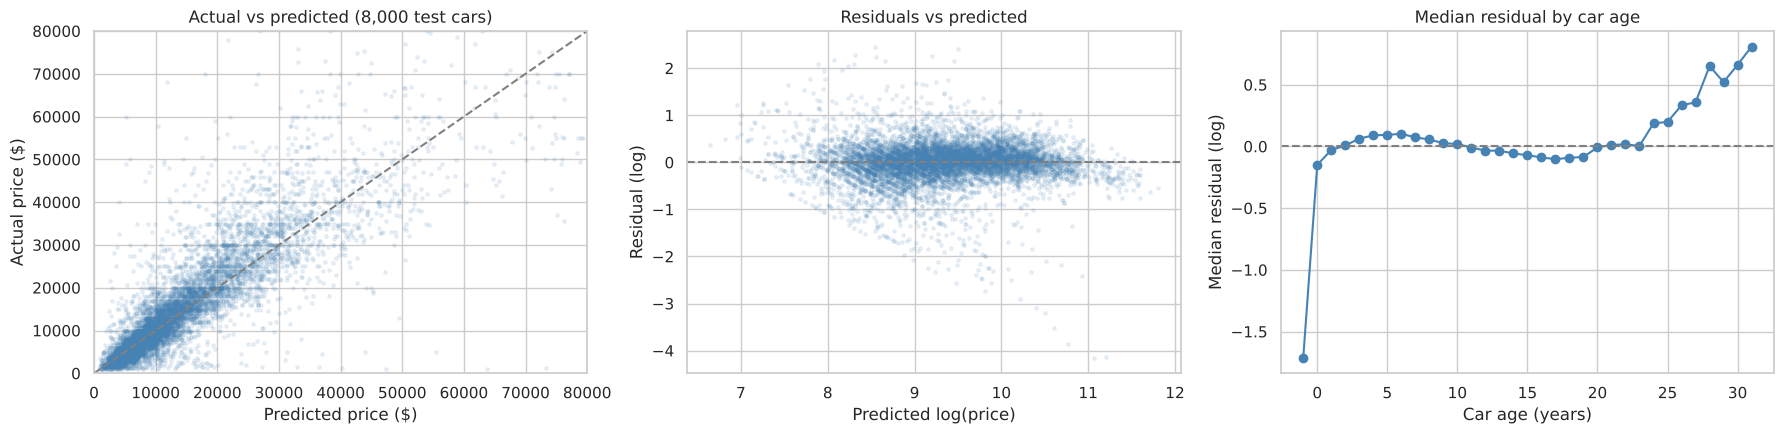

In [4]:
resid = np.log(y_test) - np.log(pred_lr)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test), 8000, replace=False)

axes[0].scatter(pred_lr[idx], y_test.values[idx], alpha=0.1, s=6, color='steelblue')
axes[0].plot([0, 80000], [0, 80000], color='grey', ls='--')
axes[0].set(xlim=(0, 80000), ylim=(0, 80000), xlabel='Predicted price ($)', ylabel='Actual price ($)',
            title='Actual vs predicted (8,000 test cars)')

axes[1].scatter(np.log(pred_lr)[idx], resid.values[idx], alpha=0.1, s=6, color='steelblue')
axes[1].axhline(0, color='grey', ls='--')
axes[1].set(xlabel='Predicted log(price)', ylabel='Residual (log)', title='Residuals vs predicted')

age_resid = resid.groupby(X_test['car_age']).median()
axes[2].plot(age_resid.index, age_resid.values, marker='o', color='steelblue')
axes[2].axhline(0, color='grey', ls='--')
axes[2].set(xlabel='Car age (years)', ylabel='Median residual (log)', title='Median residual by car age')
plt.tight_layout()
plt.show()

- **Actual vs predicted:** the points follow the diagonal, with wider spread for expensive cars (normal for prices).
- **Residuals vs predicted:** centred on 0 with no strong trend. The long tail below 0 are cars listed far below
  what their details suggest (damaged, parts cars or low "bait" prices).
- **Residuals by age:** close to 0 for cars aged 1–20, but **cars older than about 25 years are under-predicted**
  (they hold their value better than the straight line says), and the few listings with model year 2022
  (age −1, probably mistyped years) are over-predicted. Even on the log scale the age effect is curved.
  A linear model cannot bend, which is why the tree models in notebook 05 should do better.

## 3. Regularization: Ridge, Lasso, ElasticNet (lesson 12)

Each is tuned with `GridSearchCV` on the training set, scored by MAE on the log scale (which rewards small
*percentage* errors, the same thing the dollar MAE on a log model favours). Ridge is cheap, so it gets 5 folds;
Lasso and ElasticNet are slower on 180,000 rows × 430 columns and use 3 folds.

In [5]:
ridge = GridSearchCV(make_pipeline(linear_preprocessor(), Ridge()),
                     {'ridge__alpha': [0.1, 1, 10, 30, 100, 300]},
                     cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
ridge.fit(X_train, y_train_log)
print('Ridge best alpha:', ridge.best_params_)
pd.DataFrame(ridge.cv_results_)[['param_ridge__alpha', 'mean_test_score']].round(4)

Ridge best alpha: {'ridge__alpha': 1}


,param_ridge__alpha,mean_test_score
0,0.1,-0.2836
1,1.0,-0.2836
2,10.0,-0.2837
3,30.0,-0.2845
4,100.0,-0.2879
5,300.0,-0.2950


In [6]:
lasso = GridSearchCV(make_pipeline(linear_preprocessor(), Lasso(max_iter=5000)),
                     {'lasso__alpha': [0.00003, 0.0001, 0.0003, 0.001, 0.01]},
                     cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
lasso.fit(X_train, y_train_log)
print('Lasso best alpha:', lasso.best_params_)
pd.DataFrame(lasso.cv_results_)[['param_lasso__alpha', 'mean_test_score']].round(4)

Lasso best alpha: {'lasso__alpha': 3e-05}


,param_lasso__alpha,mean_test_score
0,0.0000,-0.2840
1,0.0001,-0.2870
2,0.0003,-0.2958
3,0.0010,-0.3100
4,0.0100,-0.3577


In [7]:
enet = GridSearchCV(make_pipeline(linear_preprocessor(), ElasticNet(max_iter=5000)),
                    {'elasticnet__alpha': [0.0001, 0.001], 'elasticnet__l1_ratio': [0.2, 0.5, 0.8]},
                    cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
enet.fit(X_train, y_train_log)
print('ElasticNet best:', enet.best_params_)

ElasticNet best: {'elasticnet__alpha': 0.0001, 'elasticnet__l1_ratio': 0.2}


In [8]:
for name, search in [('Ridge', ridge), ('Lasso', lasso), ('ElasticNet', enet)]:
    save_params(name, search.best_params_)
    table = save_result(evaluate(name, y_test, np.exp(search.predict(X_test))))
table

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
1,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
2,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
3,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
4,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550


In [9]:
coef_lasso = lasso.best_estimator_[-1].coef_
print(f'Lasso set {np.sum(coef_lasso == 0)} of {len(coef_lasso)} coefficients to exactly 0')

Lasso set 45 of 430 coefficients to exactly 0


- **Regularization does not help here.** The best Ridge penalty is `alpha = 1`, almost no penalty, and the four
  models are within \$3 of each other on the test set (\$4,149–4,151 MAE).
- The reason is the data size: 166,115 training rows for 430 columns, so plain Linear Regression is not overfitting.
  Lesson 12: regularization helps most when there are many features compared with rows.
- Lasso set **45 of 430 coefficients to exactly 0** with no loss in accuracy, so a simpler model is possible.

## 4. What drives price? Reading the coefficients

With a log target, a coefficient `b` means the price is multiplied by `exp(b)`: **(exp(b) − 1) × 100 = % change
in price**, holding the other features fixed. For one-hot columns the change is relative to the dropped
(first, alphabetical) level of that feature. For `car_age` the scaled coefficient is divided by the scaler's
standard deviation to get the effect of **one extra year**.

In [10]:
best_ridge = ridge.best_estimator_
names = best_ridge[0].get_feature_names_out()
coefs = pd.Series(best_ridge[-1].coef_, index=names)

age_scale = best_ridge[0].named_transformers_['age'].scale_[0]
per_year = (np.exp(coefs['car_age'] / age_scale) - 1) * 100
print(f'One extra year of age: {per_year:.1f}% price')

numeric = ['car_age', 'odometer', 'cylinders_num']
effects = ((np.exp(coefs) - 1) * 100).rename('pct_change').to_frame()
effects['unit'] = np.where(effects.index.isin(numeric), 'per 1 standard deviation (scaled feature)',
                           'vs the dropped (reference) level of the feature')
effects.loc['car_age_per_year'] = [per_year, 'per 1 extra year of age']
effects['feature'] = [n if n in numeric + ['car_age_per_year'] else n.split('_')[0] for n in effects.index]
effects.round(2).to_csv('../results/linear_coefficients.csv')

reference = {col: sorted(X_train[col].fillna('unknown').unique())[0]
             for col in ['condition', 'fuel', 'title_status', 'transmission', 'drive', 'type']}
print('Reference (dropped) levels:', reference)

One extra year of age: -6.7% price
Reference (dropped) levels: {'condition': 'excellent', 'fuel': 'diesel', 'title_status': 'clean', 'transmission': 'automatic', 'drive': '4wd', 'type': 'SUV'}


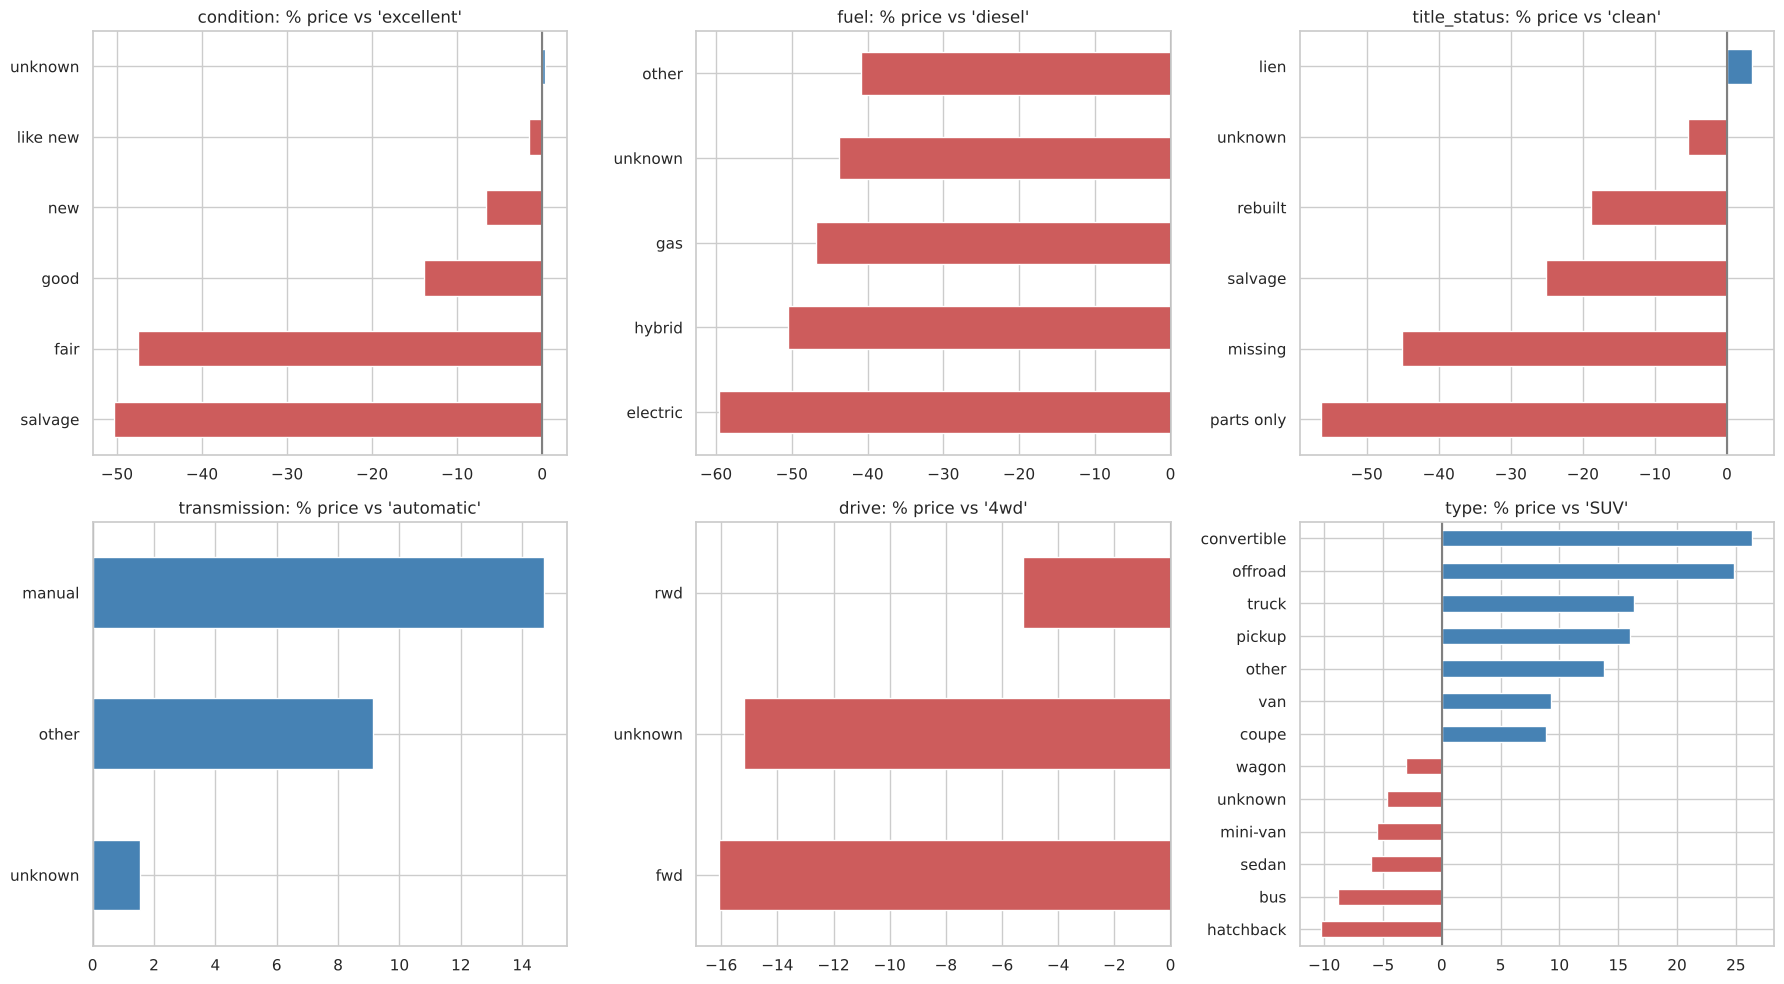

In [11]:
show = ['condition_', 'fuel_', 'title_status_', 'transmission_', 'drive_', 'type_']
small = effects[[any(n.startswith(s) for s in show) for n in effects.index]]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, prefix in zip(axes.flat, show):
    part = small[small.index.str.startswith(prefix)]['pct_change'].sort_values()
    part.index = part.index.str.replace(prefix, '')
    part.plot(kind='barh', ax=ax, color=np.where(part > 0, 'steelblue', 'indianred'))
    ax.axvline(0, color='grey')
    ax.set_title(f"{prefix.rstrip('_')}: % price vs '{reference[prefix.rstrip('_')]}'")
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [12]:
for prefix in show:
    part = small[small.index.str.startswith(prefix)]['pct_change'].round(1)
    print(prefix.rstrip('_'), '| reference:', reference[prefix.rstrip('_')], '|', part.to_dict())

condition | reference: excellent | {'condition_fair': -47.6, 'condition_good': -13.9, 'condition_like new': -1.6, 'condition_new': -6.7, 'condition_salvage': -50.3, 'condition_unknown': 0.4}
fuel | reference: diesel | {'fuel_electric': -59.6, 'fuel_gas': -46.8, 'fuel_hybrid': -50.5, 'fuel_other': -40.9, 'fuel_unknown': -43.7}
title_status | reference: clean | {'title_status_lien': 3.5, 'title_status_missing': -45.1, 'title_status_parts only': -56.3, 'title_status_rebuilt': -18.9, 'title_status_salvage': -25.2, 'title_status_unknown': -5.4}
transmission | reference: automatic | {'transmission_manual': 14.7, 'transmission_other': 9.1, 'transmission_unknown': 1.5}
drive | reference: 4wd | {'drive_fwd': -16.1, 'drive_rwd': -5.2, 'drive_unknown': -15.2}
type | reference: SUV | {'type_bus': -8.8, 'type_convertible': 26.4, 'type_coupe': 8.9, 'type_hatchback': -10.3, 'type_mini-van': -5.5, 'type_offroad': 24.8, 'type_other': 13.8, 'type_pickup': 16.0, 'type_sedan': -6.0, 'type_truck': 16.4, 't

Effects below hold every other feature fixed (same age, mileage, make, model, state, ...):

| Feature | Effect on price |
| --- | --- |
| **Age** | **−6.7% per extra year** |
| Title (vs clean) | rebuilt −18.9%, salvage −25.2%, missing −45.1%, parts only −56.3% |
| Condition (vs excellent) | good −13.9%, fair −47.6%, salvage −50.3% |
| Fuel (vs diesel) | gas −46.8%, hybrid −50.5%, electric −59.6% → a large diesel premium |
| Drive (vs 4wd) | fwd −16.1%, rwd −5.2% |
| Body type (vs SUV) | pickup +16.0%, truck +16.4%, convertible +26.4%, offroad +24.8%, sedan −6.0%, hatchback −10.3% |

Two results need care, because coefficients show association, not cause (lesson 05):

- **"new" (−6.7%) and "like new" (−1.6%) are not above "excellent".** Once age and mileage are in the model,
  the seller's condition label adds little at the top end; dealers also use these labels loosely.
- **Manual +14.7% vs automatic.** In 2021 listings, manual gearboxes are mostly on sports cars, Jeep Wranglers
  and work trucks, which hold value. Making a car manual would not raise its price.

All coefficients are saved in `results/linear_coefficients.csv`.

## 5. Summary

In [13]:
pd.read_csv('../results/metrics.csv').round(3)

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000
1,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
2,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
3,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
4,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550


- **Linear Regression on log(price): MAE \$4,151 on the test set**, 57% lower than the baseline (\$9,675).
  R² 0.68. The typical (median) error is \$2,151.
- `log(price)` beats raw price on every metric (cross-validated).
- Ridge, Lasso and ElasticNet give the same accuracy: with 166k rows the model is not overfitting.
- The linear model is the **explaining model**: each year costs about 6.7% of value, a salvage title about 25%,
  and diesel carries a large premium.
- Its weakness is visible in the residuals: the age effect is curved, and features interact. Notebook 05 tests
  tree models, which can follow both.